# 💰 Advanced Personal Expense Tracker (CLI)

A beginner-friendly but feature-rich expense tracker written in pure Python 3.
Everything is stored in plain CSV files, so no database or server is needed.

| Feature | Where it lives |
|---|---|
| Income / expense management, search & filter | Menu 1 – 4 |
| Monthly budget with 80 % / 100 % warnings | Menu 5 |
| Monthly summary, month-to-month comparison | Menu 6 – 7 |
| Highest expense category | Menu 8 |
| Savings calculator and savings goal | Menu 9 |
| Charts (pie, bar, line) saved as PNG | Menu 10 |
| Export to CSV / Excel / monthly report | Menu 11 |

**How to use**

1. Run the cells from top to bottom (`Run All`).
2. The last cell starts the menu. Type a number in the input box that appears under the cell.
3. *(Optional)* Run the **sample data** cell at the very end first if you want to try the app with demo records.

**Files created next to this notebook**

* `transactions.csv`, `budgets.csv`, `goals.csv` – permanent storage
* `charts/` – PNG charts
* `reports/` – exported CSV, Excel and monthly reports

## Step 0 – Optional libraries

The app works without them, but charts need **matplotlib** and Excel export needs **openpyxl**.
Uncomment the line below and run it once if they are not installed.

In [1]:
# !pip install matplotlib openpyxl

## Step 1 – Imports and configuration

All settings (file names, categories, currency symbol, warning levels) are kept in one place so they are easy to change.

In [2]:
import csv
import math
import os
from collections import defaultdict
from datetime import date, datetime

# ---- Optional libraries: the app still runs if they are missing ----
try:
    import matplotlib.pyplot as plt
    HAS_MATPLOTLIB = True
except ImportError:
    HAS_MATPLOTLIB = False

try:
    from openpyxl import Workbook
    from openpyxl.styles import Alignment, Font, PatternFill
    from openpyxl.utils import get_column_letter
    HAS_OPENPYXL = True
except ImportError:
    HAS_OPENPYXL = False

# ---- File names and folders ----
TRANSACTIONS_FILE = "transactions.csv"
BUDGETS_FILE = "budgets.csv"
GOALS_FILE = "goals.csv"
CHART_DIR = "charts"
REPORT_DIR = "reports"

# Column headers for every CSV file (used when the files are auto-created)
FILE_HEADERS = {
    TRANSACTIONS_FILE: ["id", "date", "type", "amount", "category", "description"],
    BUDGETS_FILE: ["month", "budget"],
    GOALS_FILE: ["goal_name", "target_amount", "created_on"],
}

# ---- App settings ----
CURRENCY = "$"                 # change to any symbol you like
DATE_FMT = "%Y-%m-%d"          # how dates are typed and stored
MONTH_FMT = "%Y-%m"            # how months are typed and stored
MAX_AMOUNT = 1_000_000_000     # sanity limit to catch typing mistakes
WARN_LEVEL = 80                # budget warning at 80 %
LIMIT_LEVEL = 100              # budget alert at 100 %

TYPE_INCOME = "Income"
TYPE_EXPENSE = "Expense"

EXPENSE_CATEGORIES = ["Food", "Travel", "Shopping", "Education",
                      "Bills", "Entertainment", "Healthcare", "Others"]
INCOME_CATEGORIES = ["Salary", "Business", "Freelance", "Investment",
                     "Gift", "Others"]

print("Configuration loaded.")
print("Matplotlib:", "available" if HAS_MATPLOTLIB else "NOT installed (charts disabled)")
print("OpenPyXL  :", "available" if HAS_OPENPYXL else "NOT installed (Excel export disabled)")

Configuration loaded.
Matplotlib: available
OpenPyXL  : available


## Step 2 – CSV storage layer

Only these functions touch the CSV files. New transactions are **appended** so existing records are never lost.
Damaged rows are skipped instead of crashing the program.

In [3]:
def ensure_files():
    # Create the data files (with headers) and output folders if they do not exist.
    os.makedirs(CHART_DIR, exist_ok=True)
    os.makedirs(REPORT_DIR, exist_ok=True)
    for path, header in FILE_HEADERS.items():
        if not os.path.exists(path):
            with open(path, "w", newline="", encoding="utf-8") as f:
                csv.writer(f).writerow(header)


def read_rows(path):
    # Read a CSV file into a list of dictionaries.
    try:
        with open(path, newline="", encoding="utf-8") as f:
            return list(csv.DictReader(f))
    except FileNotFoundError:
        ensure_files()
        return []
    except OSError as err:
        print(f"  ✗ Could not read {path}: {err}")
        return []


# ---------------- transactions ----------------
def load_transactions():
    # Return all valid transactions as dictionaries with proper data types.
    transactions, skipped = [], 0
    for row in read_rows(TRANSACTIONS_FILE):
        try:
            datetime.strptime(row["date"], DATE_FMT)       # validates the date
            transactions.append({
                "id": int(row["id"]),
                "date": row["date"],
                "type": row["type"],
                "amount": float(row["amount"]),
                "category": row["category"],
                "description": row["description"],
            })
        except (ValueError, KeyError, TypeError):
            skipped += 1                                  # ignore corrupted rows
    if skipped:
        print(f"  (Note: {skipped} damaged row(s) in {TRANSACTIONS_FILE} were ignored)")
    return transactions


def append_transaction(tx_type, date_str, amount, category, description):
    # Add ONE new row at the end of the file (existing rows stay untouched).
    existing = load_transactions()
    new_id = max((t["id"] for t in existing), default=0) + 1
    record = {"id": new_id, "date": date_str, "type": tx_type,
              "amount": round(amount, 2), "category": category,
              "description": description}
    with open(TRANSACTIONS_FILE, "a", newline="", encoding="utf-8") as f:
        csv.writer(f).writerow([record[k] for k in FILE_HEADERS[TRANSACTIONS_FILE]])
    return record


# ---------------- budgets ----------------
def load_budgets():
    # Return {"YYYY-MM": budget_amount}
    budgets = {}
    for row in read_rows(BUDGETS_FILE):
        try:
            budgets[row["month"]] = float(row["budget"])
        except (ValueError, KeyError, TypeError):
            continue
    return budgets


def save_budget(month, amount):
    # Insert or update the budget of one month, then rewrite the (small) file.
    budgets = load_budgets()
    budgets[month] = round(amount, 2)
    with open(BUDGETS_FILE, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(FILE_HEADERS[BUDGETS_FILE])
        for m in sorted(budgets):
            writer.writerow([m, budgets[m]])


# ---------------- savings goals ----------------
def load_goals():
    goals = []
    for row in read_rows(GOALS_FILE):
        try:
            goals.append({"name": row["goal_name"],
                          "target": float(row["target_amount"]),
                          "created_on": row["created_on"]})
        except (ValueError, KeyError, TypeError):
            continue
    return goals


def get_active_goal():
    # The most recently saved goal is the active one.
    goals = load_goals()
    return goals[-1] if goals else None


def save_goal(name, target):
    with open(GOALS_FILE, "a", newline="", encoding="utf-8") as f:
        csv.writer(f).writerow([name, round(target, 2), date.today().strftime(DATE_FMT)])


ensure_files()
print("Storage ready:", ", ".join(FILE_HEADERS))

Storage ready: transactions.csv, budgets.csv, goals.csv


## Step 3 – Input validation and display helpers

Every question the program asks goes through one of these helpers, so validation is written **once** and reused everywhere.

In [4]:
# ======================= INPUT HELPERS =======================
def ask(prompt):
    return input(prompt).strip()


def get_date(prompt="Date (YYYY-MM-DD) [Enter = today]: ", allow_blank=False):
    # Keep asking until a real, non-future date is typed.
    # Blank input = today (or None when allow_blank=True, used by filters).
    while True:
        raw = ask(prompt)
        if not raw:
            return None if allow_blank else date.today().strftime(DATE_FMT)
        try:
            parsed = datetime.strptime(raw, DATE_FMT).date()
        except ValueError:
            print("  ✗ Invalid date. Use YYYY-MM-DD, e.g. 2026-11-09.")
            continue
        if parsed > date.today():
            print("  ✗ Date cannot be in the future.")
        elif parsed.year < 2000:
            print("  ✗ Year must be 2000 or later.")
        else:
            return parsed.strftime(DATE_FMT)      # normalised, e.g. 2026-1-5 -> 2026-01-05


def get_amount(prompt="Amount: ", allow_blank=False):
    # Accept only positive, finite numbers (commas allowed, rounded to 2 decimals).
    while True:
        raw = ask(prompt).replace(",", "")
        if not raw and allow_blank:
            return None
        try:
            value = float(raw)
        except ValueError:
            print("  ✗ Please enter a number, e.g. 250 or 99.50.")
            continue
        if not math.isfinite(value) or value <= 0:
            print("  ✗ Amount must be greater than zero.")
        elif value > MAX_AMOUNT:
            print(f"  ✗ Amount is too large (max {MAX_AMOUNT:,}).")
        else:
            return round(value, 2)


def current_month():
    return date.today().strftime(MONTH_FMT)


def get_month(prompt="Month (YYYY-MM) [Enter = current month]: "):
    while True:
        raw = ask(prompt)
        if not raw:
            return current_month()
        try:
            return datetime.strptime(raw, MONTH_FMT).strftime(MONTH_FMT)
        except ValueError:
            print("  ✗ Invalid month. Use YYYY-MM, e.g. 2026-11.")


def get_month_or_all(prompt="Month (YYYY-MM), 'all', or Enter = current month: "):
    # Returns a month string, or None meaning "all time".
    while True:
        raw = ask(prompt)
        if raw.lower() == "all":
            return None
        if not raw:
            return current_month()
        try:
            return datetime.strptime(raw, MONTH_FMT).strftime(MONTH_FMT)
        except ValueError:
            print("  ✗ Invalid month. Use YYYY-MM or type 'all'.")


def choose_category(categories, allow_blank=False):
    # Show a numbered list and accept either the number or the name.
    for i, name in enumerate(categories, 1):
        print(f"   {i}. {name}")
    while True:
        raw = ask("Category (number or name)" + (" [Enter = any]: " if allow_blank else ": "))
        if not raw and allow_blank:
            return None
        if raw.isdigit() and 1 <= int(raw) <= len(categories):
            return categories[int(raw) - 1]
        for name in categories:
            if raw.lower() == name.lower():
                return name
        print("  ✗ Invalid category. Pick one from the list.")


def get_text(prompt="Description (optional): "):
    return ask(prompt)[:100] or "-"


def pause():
    ask("\nPress Enter to continue...")


# ======================= DISPLAY HELPERS =======================
def money(value):
    sign = "-" if value < 0 else ""
    return f"{sign}{CURRENCY}{abs(value):,.2f}"


def bar(percent, width=20):
    # Text progress bar, e.g. [██████░░░░]
    filled = int(min(max(percent, 0), 100) / 100 * width)
    return "[" + "█" * filled + "░" * (width - filled) + "]"


def heading(title):
    print("\n" + "=" * 10 + f" {title.upper()} " + "=" * 10)


def print_table(headers, rows, aligns=None):
    # Print a neat ASCII table. aligns is a string like "lrr" (l = left, r = right).
    if not rows:
        print("  (no records found)")
        return
    aligns = aligns or "l" * len(headers)
    cells = [[str(c) for c in row] for row in rows]
    widths = [max(len(str(h)), *(len(r[i]) for r in cells)) for i, h in enumerate(headers)]

    def format_row(values):
        parts = [v.rjust(w) if a == "r" else v.ljust(w)
                 for v, w, a in zip(values, widths, aligns)]
        return "| " + " | ".join(parts) + " |"

    separator = "+-" + "-+-".join("-" * w for w in widths) + "-+"
    print(separator)
    print(format_row([str(h) for h in headers]))
    print(separator)
    for row in cells:
        print(format_row(row))
    print(separator)


print("Helpers loaded.")

Helpers loaded.


## Step 4 – Calculation (analytics) functions

These functions do **only maths** – they never print or ask questions. Because of that, the menu screens, the text report and the Excel export can all share them (no duplicate code).

In [5]:
def month_of(transaction):
    return transaction["date"][:7]                    # "2026-11-09" -> "2026-11"


def total_by_type(transactions, tx_type, month=None):
    # Sum of income or expenses (for one month, or all time when month is None).
    return sum(t["amount"] for t in transactions
               if t["type"] == tx_type and (month is None or month_of(t) == month))


def category_totals(transactions, month=None):
    # {category: total spent}, sorted from highest to lowest.
    totals = defaultdict(float)
    for t in transactions:
        if t["type"] == TYPE_EXPENSE and (month is None or month_of(t) == month):
            totals[t["category"]] += t["amount"]
    return dict(sorted(totals.items(), key=lambda kv: kv[1], reverse=True))


def monthly_totals(transactions):
    # {"2026-10": {"income": x, "expense": y}, ...} in date order.
    data = defaultdict(lambda: {"income": 0.0, "expense": 0.0})
    for t in transactions:
        key = "income" if t["type"] == TYPE_INCOME else "expense"
        data[month_of(t)][key] += t["amount"]
    return dict(sorted(data.items()))


def pct_change(old, new):
    # Percentage change from old to new; None when old is 0 (cannot divide).
    if old == 0:
        return None
    return (new - old) / old * 100


def describe_change(old, new):
    # Human-readable change such as "▲ 12.5% (increased)".
    change = pct_change(old, new)
    if change is None:
        return "N/A (no spending before)" if new else "No change"
    if abs(change) < 0.05:
        return "= 0.0% (no change)"
    if change > 0:
        return f"▲ {change:.1f}% (increased)"
    return f"▼ {abs(change):.1f}% (decreased)"


def monthly_table(transactions):
    # One row per month: month, income, expense, savings, expense-change vs previous month.
    rows, previous = [], None
    for month, v in monthly_totals(transactions).items():
        change = describe_change(previous["expense"], v["expense"]) if previous else "-"
        rows.append([month, v["income"], v["expense"], v["income"] - v["expense"], change])
        previous = v
    return rows


def budget_status(transactions, month):
    # Compare a month's spending with its budget. Returns None if no budget is set.
    budget = load_budgets().get(month)
    if budget is None:
        return None
    spent = total_by_type(transactions, TYPE_EXPENSE, month)
    return {"month": month, "budget": budget, "spent": spent,
            "remaining": budget - spent, "pct": spent / budget * 100}


def budget_warning(status):
    # Return a warning message at 80 % and 100 % of the budget (else None).
    if status is None:
        return None
    if status["pct"] >= LIMIT_LEVEL:
        over = -status["remaining"]
        return (f"*** ALERT: You have reached {status['pct']:.1f}% of your budget! "
                f"({'Over by ' + money(over) if over > 0 else 'Budget fully used'}) ***")
    if status["pct"] >= WARN_LEVEL:
        return (f"*** WARNING: You have used {status['pct']:.1f}% of your budget "
                f"(only {money(status['remaining'])} left). ***")
    return None


def goal_info(savings):
    # Progress towards the active savings goal (None when no goal exists).
    goal = get_active_goal()
    if goal is None:
        return None
    progress = max(savings, 0) / goal["target"] * 100
    return {"name": goal["name"], "target": goal["target"],
            "remaining": max(goal["target"] - savings, 0), "pct": progress}


def build_summary(transactions, month):
    # Collect every number needed for the monthly summary in one dictionary.
    income = total_by_type(transactions, TYPE_INCOME, month)
    expense = total_by_type(transactions, TYPE_EXPENSE, month)
    # Total savings = all income minus all expenses up to the end of this month
    cumulative = sum((t["amount"] if t["type"] == TYPE_INCOME else -t["amount"])
                     for t in transactions if month_of(t) <= month)
    categories = category_totals(transactions, month)
    return {
        "month": month, "income": income, "expense": expense,
        "balance": income - expense, "savings": cumulative,
        "categories": categories,
        "top": next(iter(categories.items()), None),   # first item = highest
        "budget": budget_status(transactions, month),
        "goal": goal_info(cumulative),
    }


def category_rows(categories):
    # Rows for a category table: name, amount, share %, bar.
    total = sum(categories.values()) or 1
    return [[name, money(amount), f"{amount / total * 100:.1f}%", bar(amount / total * 100)]
            for name, amount in categories.items()]


def summary_lines(s):
    # Build the summary as plain text lines (used on screen AND in report files).
    lines = [
        f"Month                    : {s['month']}",
        f"Total Income             : {money(s['income'])}",
        f"Total Expenses           : {money(s['expense'])}",
        f"Remaining Balance        : {money(s['balance'])}   (income - expenses this month)",
        f"Total Savings            : {money(s['savings'])}   (all income - all expenses to date)",
    ]
    if s["top"]:
        lines.append(f"Highest Expense Category : {s['top'][0]} ({money(s['top'][1])})")
    else:
        lines.append("Highest Expense Category : none (no expenses this month)")

    b = s["budget"]
    if b:
        lines += [f"Monthly Budget           : {money(b['budget'])}",
                  f"Budget Utilization       : {b['pct']:.1f}% {bar(b['pct'])}",
                  f"Remaining Budget         : {money(b['remaining'])}"]
        warning = budget_warning(b)
        if warning:
            lines.append(warning)
    else:
        lines.append("Budget                   : not set for this month (use menu option 5)")

    g = s["goal"]
    if g:
        lines += [f"Savings Goal             : {g['name']} - {money(g['target'])}",
                  f"Savings Goal Progress    : {g['pct']:.1f}% {bar(g['pct'])}",
                  f"Still Needed             : {money(g['remaining'])}"]
    else:
        lines.append("Savings Goal             : not set (use menu option 9)")
    return lines


print("Analytics functions loaded.")

Analytics functions loaded.


## Step 5 – Income and expense management (menu 1 – 4)

* **Add Income / Add Expense** share one function (`add_transaction`).
* **View** has sub-options (all / income / expenses / one month).
* **Search** combines keyword, category, date range and amount range filters – leave any filter blank to skip it.

In [6]:
TX_HEADERS = ["ID", "Date", "Type", "Category", "Amount", "Description"]


def add_transaction(tx_type):
    # One function adds both income and expenses.
    categories = INCOME_CATEGORIES if tx_type == TYPE_INCOME else EXPENSE_CATEGORIES
    heading(f"Add {tx_type}")
    date_str = get_date()
    amount = get_amount()
    category = choose_category(categories)
    description = get_text()

    try:
        record = append_transaction(tx_type, date_str, amount, category, description)
    except OSError as err:
        print(f"  ✗ Could not save the record: {err}")
        return
    print(f"\n  ✓ {tx_type} saved: {money(record['amount'])} | {category} | {date_str} (ID {record['id']})")

    # After an expense, immediately check the budget for that month.
    if tx_type == TYPE_EXPENSE:
        warning = budget_warning(budget_status(load_transactions(), date_str[:7]))
        if warning:
            print("\n  " + warning)


def add_income():
    add_transaction(TYPE_INCOME)


def add_expense():
    add_transaction(TYPE_EXPENSE)


def show_transactions(transactions, title):
    # Print transactions newest-first, followed by totals.
    heading(title)
    ordered = sorted(transactions, key=lambda t: (t["date"], t["id"]), reverse=True)
    rows = [[t["id"], t["date"], t["type"], t["category"],
             money(t["amount"]), t["description"]] for t in ordered]
    print_table(TX_HEADERS, rows, aligns="rlllrl")
    if transactions:
        print(f"  Records: {len(transactions)}   |   "
              f"Income: {money(total_by_type(transactions, TYPE_INCOME))}   |   "
              f"Expenses: {money(total_by_type(transactions, TYPE_EXPENSE))}")


def view_transactions():
    transactions = load_transactions()
    heading("View Transactions")
    print("  1. All transactions\n  2. Income only\n  3. Expenses only\n  4. A specific month")
    choice = ask("Choose (1-4): ")
    if choice == "1":
        show_transactions(transactions, "All Transactions")
    elif choice == "2":
        show_transactions([t for t in transactions if t["type"] == TYPE_INCOME], "Income Records")
    elif choice == "3":
        show_transactions([t for t in transactions if t["type"] == TYPE_EXPENSE], "Expense Records")
    elif choice == "4":
        month = get_month()
        show_transactions([t for t in transactions if month_of(t) == month], f"Transactions - {month}")
    else:
        print("  ✗ Invalid choice.")


def search_transactions():
    transactions = load_transactions()
    heading("Search / Filter Transactions")
    print("Leave a filter blank to skip it.\n")

    keyword = ask("Keyword in description/category: ").lower()
    print("Type: 1 = Income, 2 = Expense, Enter = both")
    type_choice = ask("Type: ")
    tx_type = {"1": TYPE_INCOME, "2": TYPE_EXPENSE}.get(type_choice)
    category = choose_category(sorted(set(INCOME_CATEGORIES + EXPENSE_CATEGORIES)), allow_blank=True)
    start = get_date("From date (YYYY-MM-DD): ", allow_blank=True)
    end = get_date("To date   (YYYY-MM-DD): ", allow_blank=True)
    min_amt = get_amount("Minimum amount: ", allow_blank=True)
    max_amt = get_amount("Maximum amount: ", allow_blank=True)

    # Apply every filter that was filled in.
    results = []
    for t in transactions:
        if keyword and keyword not in t["description"].lower() and keyword not in t["category"].lower():
            continue
        if tx_type and t["type"] != tx_type:
            continue
        if category and t["category"] != category:
            continue
        if start and t["date"] < start:
            continue
        if end and t["date"] > end:
            continue
        if min_amt is not None and t["amount"] < min_amt:
            continue
        if max_amt is not None and t["amount"] > max_amt:
            continue
        results.append(t)

    show_transactions(results, f"Search Results ({len(results)} found)")


print("Transaction screens loaded.")

Transaction screens loaded.


## Step 6 – Budget, comparison, highest category and savings (menu 5, 7, 8, 9)

In [7]:
# ======================= BUDGET (menu 5) =======================
def show_budget_status(status):
    print(f"\n  Month              : {status['month']}")
    print(f"  Monthly Budget     : {money(status['budget'])}")
    print(f"  Total Spent        : {money(status['spent'])}")
    if status["remaining"] >= 0:
        print(f"  Remaining Budget   : {money(status['remaining'])}")
    else:
        print(f"  Over Budget By     : {money(-status['remaining'])}")
    print(f"  Budget Utilization : {status['pct']:.1f}% {bar(status['pct'])}")
    warning = budget_warning(status)
    if warning:
        print("\n  " + warning)


def set_monthly_budget():
    heading("Set Monthly Budget")
    month = get_month()
    current = load_budgets().get(month)
    if current is not None:
        print(f"  Current budget for {month}: {money(current)}")
    amount = get_amount("New monthly budget: ")
    try:
        save_budget(month, amount)
    except OSError as err:
        print(f"  ✗ Could not save budget: {err}")
        return
    print(f"  ✓ Budget for {month} set to {money(amount)}")
    show_budget_status(budget_status(load_transactions(), month))


# ======================= COMPARISON (menu 7) =======================
def compare_two_months(transactions, month_a, month_b):
    data = monthly_totals(transactions)
    a = data.get(month_a, {"income": 0.0, "expense": 0.0})
    b = data.get(month_b, {"income": 0.0, "expense": 0.0})
    savings_a, savings_b = a["income"] - a["expense"], b["income"] - b["expense"]
    rows = [
        ["Income", money(a["income"]), money(b["income"]), describe_change(a["income"], b["income"])],
        ["Expenses", money(a["expense"]), money(b["expense"]), describe_change(a["expense"], b["expense"])],
        ["Savings", money(savings_a), money(savings_b),
         "N/A" if savings_a <= 0 else describe_change(savings_a, savings_b)],
    ]
    print_table(["", month_a, month_b, f"Change ({month_a} -> {month_b})"], rows, aligns="lrrl")
    diff = b["expense"] - a["expense"]
    word = "more" if diff > 0 else "less"
    if diff:
        print(f"  You spent {money(abs(diff))} {word} in {month_b} than in {month_a}.")


def monthly_comparison():
    transactions = load_transactions()
    heading("Monthly Spending Comparison")
    table = monthly_table(transactions)
    if not table:
        print("  No data yet. Add some transactions first.")
        return
    rows = [[m, money(i), money(e), money(s), change] for m, i, e, s, change in table]
    print_table(["Month", "Income", "Expenses", "Savings", "Expense change vs previous month"],
                rows, aligns="lrrrl")

    if len(table) >= 2:
        print("\nCompare two specific months (press Enter to skip).")
        first = ask("First month  (YYYY-MM): ")
        if first:
            second = ask("Second month (YYYY-MM): ")
            try:
                m1 = datetime.strptime(first, MONTH_FMT).strftime(MONTH_FMT)
                m2 = datetime.strptime(second, MONTH_FMT).strftime(MONTH_FMT)
            except ValueError:
                print("  ✗ Invalid month format. Use YYYY-MM.")
                return
            print()
            compare_two_months(transactions, m1, m2)


# ======================= HIGHEST CATEGORY (menu 8) =======================
def highest_expense_category():
    transactions = load_transactions()
    heading("Highest Expense Category")
    month = get_month_or_all()
    label = month or "All time"
    categories = category_totals(transactions, month)
    if not categories:
        print(f"  No expenses found for {label}.")
        return
    print(f"\n  Category-wise spending ({label}):")
    print_table(["Category", "Spent", "Share", ""], category_rows(categories), aligns="lrrl")
    top_name, top_amount = next(iter(categories.items()))
    print(f"\n  ★ Highest spending category: {top_name} ({money(top_amount)})")


# ======================= SAVINGS (menu 9) =======================
def show_savings(transactions):
    income = total_by_type(transactions, TYPE_INCOME)
    expense = total_by_type(transactions, TYPE_EXPENSE)
    savings = income - expense                         # Savings = Total Income - Total Expenses
    print(f"\n  Total Income   : {money(income)}")
    print(f"  Total Expenses : {money(expense)}")
    print(f"  Total Savings  : {money(savings)}")
    goal = goal_info(savings)
    if goal:
        print(f"\n  Goal           : {goal['name']} ({money(goal['target'])})")
        print(f"  Progress       : {goal['pct']:.1f}% {bar(goal['pct'])}")
        if goal["remaining"] > 0:
            print(f"  Still needed   : {money(goal['remaining'])}")
        else:
            print("  🎉 Goal reached! Congratulations!")
    else:
        print("\n  No savings goal set yet.")
    return savings


def savings_calculator():
    heading("Savings Calculator")
    show_savings(load_transactions())
    if ask("\nSet or update your savings goal? (y/n): ").lower().startswith("y"):
        name = ask("Goal name (e.g. New Laptop): ")[:50] or "My Savings Goal"
        target = get_amount("Target amount: ")
        try:
            save_goal(name, target)
        except OSError as err:
            print(f"  ✗ Could not save goal: {err}")
            return
        print(f"  ✓ Goal saved: {name} - {money(target)}")
        show_savings(load_transactions())


print("Budget, comparison, category and savings screens loaded.")

Budget, comparison, category and savings screens loaded.


## Step 7 – Monthly summary (menu 6)

In [8]:
def monthly_summary():
    heading("Monthly Summary")
    month = get_month()
    transactions = load_transactions()
    summary = build_summary(transactions, month)
    print()
    for line in summary_lines(summary):
        print("  " + line)
    if summary["categories"]:
        print("\n  Category-wise spending:")
        print_table(["Category", "Spent", "Share", ""], category_rows(summary["categories"]), aligns="lrrl")


print("Monthly summary loaded.")

Monthly summary loaded.


## Step 8 – Charts with Matplotlib (menu 10)

Each chart is saved as a PNG in the `charts/` folder and also shown in the notebook.

In [9]:
def require_matplotlib():
    if not HAS_MATPLOTLIB:
        print("  ✗ Matplotlib is not installed. Run:  pip install matplotlib")
        return False
    return True


def finish_chart(filename):
    # Save the current figure as PNG, display it, then free memory.
    path = os.path.join(CHART_DIR, filename)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()
    plt.close()
    print(f"  ✓ Chart saved: {path}")


def pie_chart(transactions, month=None):
    categories = category_totals(transactions, month)
    if not categories:
        print("  No expenses to chart for that period.")
        return
    plt.figure(figsize=(7, 7))
    plt.pie(list(categories.values()), labels=list(categories.keys()),
            autopct="%1.1f%%", startangle=90)
    plt.title(f"Category-wise Expenses ({month or 'All time'})")
    finish_chart(f"category_pie_{month or 'all'}.png")


def bar_chart(transactions):
    data = monthly_totals(transactions)
    if not data:
        print("  No data to chart yet.")
        return
    months = list(data)
    positions = range(len(months))
    width = 0.38
    plt.figure(figsize=(max(7, len(months) * 1.2), 5))
    plt.bar([p - width / 2 for p in positions], [data[m]["income"] for m in months],
            width, label="Income", color="#2e9e5b")
    plt.bar([p + width / 2 for p in positions], [data[m]["expense"] for m in months],
            width, label="Expenses", color="#d9534f")
    plt.xticks(list(positions), months, rotation=45)
    plt.ylabel(f"Amount ({CURRENCY})")
    plt.title("Monthly Income vs Expenses")
    plt.legend()
    finish_chart("monthly_income_vs_expenses.png")


def line_chart(transactions):
    data = monthly_totals(transactions)
    if not data:
        print("  No data to chart yet.")
        return
    months = list(data)
    expenses = [data[m]["expense"] for m in months]
    budgets = load_budgets()
    plt.figure(figsize=(max(7, len(months) * 1.2), 5))
    plt.plot(months, expenses, marker="o", linewidth=2, color="#d9534f", label="Expenses")
    for m, value in zip(months, expenses):
        plt.annotate(f"{value:,.0f}", (m, value), textcoords="offset points",
                     xytext=(0, 8), ha="center", fontsize=8)
    # Show the budget as a dashed line for months that have one.
    budget_points = [(m, budgets[m]) for m in months if m in budgets]
    if budget_points:
        plt.plot([p[0] for p in budget_points], [p[1] for p in budget_points],
                 linestyle="--", marker="s", color="#3b6fb6", label="Budget")
    plt.xticks(rotation=45)
    plt.ylabel(f"Amount ({CURRENCY})")
    plt.title("Monthly Spending Trend")
    plt.legend()
    plt.grid(alpha=0.3)
    finish_chart("monthly_spending_trend.png")


def view_charts():
    heading("Charts")
    if not require_matplotlib():
        return
    print("  1. Pie chart  - category-wise expenses\n"
          "  2. Bar chart  - monthly income vs expenses\n"
          "  3. Line chart - monthly spending trend\n"
          "  4. Generate all charts")
    choice = ask("Choose (1-4): ")
    if choice not in {"1", "2", "3", "4"}:
        print("  ✗ Invalid choice.")
        return
    transactions = load_transactions()
    if not transactions:
        print("  No transactions yet. Add some data first.")
        return
    if choice in {"1", "4"}:
        pie_chart(transactions, get_month_or_all())
    if choice in {"2", "4"}:
        bar_chart(transactions)
    if choice in {"3", "4"}:
        line_chart(transactions)


print("Chart functions loaded.")

Chart functions loaded.


## Step 9 – Data export (menu 11)

* **All transactions → CSV** (a timestamped copy in `reports/`)
* **Excel report** – sheets for transactions, monthly summary and category spending
* **Monthly report** – a text report (plus an Excel file when OpenPyXL is available)

In [10]:
def timestamp():
    return datetime.now().strftime("%Y%m%d_%H%M%S")


def raw_tx_rows(transactions):
    # Plain (unformatted) rows for CSV / Excel files.
    ordered = sorted(transactions, key=lambda t: (t["date"], t["id"]))
    return [[t["id"], t["date"], t["type"], t["category"], t["amount"], t["description"]]
            for t in ordered]


def add_sheet(workbook, title, headers, rows):
    # Add a styled worksheet: bold coloured header, number formats, auto column width.
    sheet = workbook.create_sheet(title)
    sheet.append(headers)
    for row in rows:
        sheet.append(row)
    for cell in sheet[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill("solid", fgColor="2F5597")
        cell.alignment = Alignment(horizontal="center")
    for row in sheet.iter_rows(min_row=2):
        for cell in row:
            if isinstance(cell.value, float):
                cell.number_format = "#,##0.00"
    for index, column in enumerate(sheet.columns, 1):
        longest = max(len(str(c.value)) if c.value is not None else 0 for c in column)
        sheet.column_dimensions[get_column_letter(index)].width = min(longest + 3, 50)
    sheet.freeze_panes = "A2"


def require_openpyxl():
    if not HAS_OPENPYXL:
        print("  ✗ OpenPyXL is not installed. Run:  pip install openpyxl")
        return False
    return True


def export_transactions_csv(transactions):
    path = os.path.join(REPORT_DIR, f"all_transactions_{timestamp()}.csv")
    with open(path, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(TX_HEADERS)
        writer.writerows(raw_tx_rows(transactions))
    print(f"  ✓ Exported {len(transactions)} transactions to {path}")


def export_excel_report(transactions):
    if not require_openpyxl():
        return
    budgets = load_budgets()
    workbook = Workbook()
    workbook.remove(workbook.active)                      # drop the default empty sheet

    add_sheet(workbook, "Transactions", TX_HEADERS, raw_tx_rows(transactions))

    summary_rows = []
    for month, income, expense, savings, change in monthly_table(transactions):
        budget = budgets.get(month)
        summary_rows.append([month, income, expense, savings, change,
                             budget if budget else "Not set",
                             round(expense / budget * 100, 1) if budget else "-"])
    add_sheet(workbook, "Monthly Summary",
              ["Month", "Income", "Expenses", "Savings", "Expense Change", "Budget", "Budget Used %"],
              summary_rows)

    categories = category_totals(transactions)
    total = sum(categories.values()) or 1
    add_sheet(workbook, "Category Spending", ["Category", "Total Spent", "Share %"],
              [[c, a, round(a / total * 100, 1)] for c, a in categories.items()])

    path = os.path.join(REPORT_DIR, f"expense_report_{timestamp()}.xlsx")
    workbook.save(path)
    print(f"  ✓ Excel report saved: {path}")


def generate_monthly_report(transactions):
    month = get_month()
    summary = build_summary(transactions, month)
    month_tx = [t for t in transactions if month_of(t) == month]

    # ---- text report ----
    lines = ["PERSONAL EXPENSE TRACKER - MONTHLY REPORT",
             f"Generated: {datetime.now():%Y-%m-%d %H:%M}", "=" * 60, ""]
    lines += summary_lines(summary)
    lines += ["", "Category-wise spending:"]
    lines += [f"  {n:<15} {a:>14} {p:>7}" for n, a, p, _ in category_rows(summary["categories"])] or ["  (none)"]
    lines += ["", "Transactions:"]
    lines += [f"  {t['date']}  {t['type']:<8} {t['category']:<14} {money(t['amount']):>14}  {t['description']}"
              for t in sorted(month_tx, key=lambda t: (t["date"], t["id"]))] or ["  (none)"]
    text_path = os.path.join(REPORT_DIR, f"monthly_report_{month}.txt")
    with open(text_path, "w", encoding="utf-8") as f:
        f.write("\n".join(lines) + "\n")
    print(f"  ✓ Text report saved: {text_path}")

    # ---- Excel version (optional) ----
    if HAS_OPENPYXL:
        workbook = Workbook()
        workbook.remove(workbook.active)
        metrics = [[line.split(":", 1)[0].strip(), line.split(":", 1)[1].strip()]
                   for line in summary_lines(summary) if ":" in line]
        add_sheet(workbook, "Summary", ["Metric", "Value"], metrics)
        categories = summary["categories"]
        total = sum(categories.values()) or 1
        add_sheet(workbook, "Category Spending", ["Category", "Spent", "Share %"],
                  [[c, a, round(a / total * 100, 1)] for c, a in categories.items()])
        add_sheet(workbook, "Transactions", TX_HEADERS, raw_tx_rows(month_tx))
        xlsx_path = os.path.join(REPORT_DIR, f"monthly_report_{month}.xlsx")
        workbook.save(xlsx_path)
        print(f"  ✓ Excel report saved: {xlsx_path}")


def export_reports():
    heading("Export Reports")
    print("  1. Export all transactions to CSV\n"
          "  2. Export full Excel report\n"
          "  3. Generate monthly report")
    choice = ask("Choose (1-3): ")
    transactions = load_transactions()
    if choice not in {"1", "2", "3"}:
        print("  ✗ Invalid choice.")
        return
    if not transactions:
        print("  No transactions to export yet.")
        return
    try:
        if choice == "1":
            export_transactions_csv(transactions)
        elif choice == "2":
            export_excel_report(transactions)
        else:
            generate_monthly_report(transactions)
    except PermissionError:
        print("  ✗ Permission denied. Close the file if it is open in Excel and try again.")
    except OSError as err:
        print(f"  ✗ Could not write the file: {err}")


print("Export functions loaded.")

Export functions loaded.


## Step 10 – CLI dashboard (main menu)

The menu is a list of `(label, function)` pairs, so adding a feature later only needs one new line.

In [11]:
MENU = [
    ("Add Income", add_income),
    ("Add Expense", add_expense),
    ("View Transactions", view_transactions),
    ("Search Transactions", search_transactions),
    ("Set Monthly Budget", set_monthly_budget),
    ("Monthly Summary", monthly_summary),
    ("Monthly Spending Comparison", monthly_comparison),
    ("Highest Expense Category", highest_expense_category),
    ("Savings Calculator", savings_calculator),
    ("View Charts", view_charts),
    ("Export Reports", export_reports),
    ("Exit", None),
]
EXIT_CHOICE = str(len(MENU))


def show_menu():
    print("\n" + "=" * 10 + " PERSONAL EXPENSE TRACKER " + "=" * 10 + "\n")
    for number, (label, _) in enumerate(MENU, 1):
        print(f"{number:>2}. {label}")
    print()


def main():
    ensure_files()
    while True:
        show_menu()
        try:
            choice = ask("Enter your choice: ")
            if choice == EXIT_CHOICE:
                print("\nThank you for using Personal Expense Tracker. Goodbye! 👋")
                break
            if not choice.isdigit() or not 1 <= int(choice) <= len(MENU) - 1:
                print(f"  ✗ Please enter a number between 1 and {EXIT_CHOICE}.")
                continue
            MENU[int(choice) - 1][1]()                 # run the chosen feature
            pause()
        except KeyboardInterrupt:
            print("\n  Cancelled - back to the main menu.")
        except EOFError:
            print("\n  Input closed. Exiting.")
            break
        except Exception as err:                       # last-resort safety net
            print(f"\n  ✗ Unexpected error: {err}")


print("Menu ready. Run the next cell to start the app.")

Menu ready. Run the next cell to start the app.


## 🧪 Optional – Load sample data

Want to try the charts and reports straight away? Uncomment the last line of the cell below and run it **once** (before starting the app).
It only adds data when `transactions.csv` is empty, so your real records are never touched.

In [12]:
def load_sample_data():
    ensure_files()
    if load_transactions():
        print("transactions.csv already has data - sample data NOT added.")
        return
    today = date.today()
    sample = [  # (months_ago, day, type, amount, category, description)
        (2, 1, TYPE_INCOME, 52000, "Salary", "Monthly salary"),
        (2, 5, TYPE_EXPENSE, 9500, "Bills", "Rent share and electricity"),
        (2, 9, TYPE_EXPENSE, 6200, "Food", "Groceries and dining"),
        (2, 14, TYPE_EXPENSE, 3100, "Travel", "Fuel and cab rides"),
        (2, 20, TYPE_EXPENSE, 4500, "Shopping", "Clothes"),
        (1, 1, TYPE_INCOME, 52000, "Salary", "Monthly salary"),
        (1, 3, TYPE_INCOME, 6000, "Freelance", "Side project"),
        (1, 5, TYPE_EXPENSE, 9500, "Bills", "Rent share and electricity"),
        (1, 8, TYPE_EXPENSE, 7800, "Food", "Groceries and dining"),
        (1, 12, TYPE_EXPENSE, 2400, "Entertainment", "Movies and streaming"),
        (1, 18, TYPE_EXPENSE, 5200, "Education", "Online course"),
        (1, 22, TYPE_EXPENSE, 1800, "Healthcare", "Doctor visit"),
        (0, 1, TYPE_INCOME, 52000, "Salary", "Monthly salary"),
        (0, 2, TYPE_EXPENSE, 9500, "Bills", "Rent share and electricity"),
        (0, 4, TYPE_EXPENSE, 8100, "Food", "Groceries and dining"),
        (0, 6, TYPE_EXPENSE, 6700, "Shopping", "Electronics accessories"),
        (0, 8, TYPE_EXPENSE, 2900, "Travel", "Weekend trip"),
    ]
    for months_ago, day, tx_type, amount, category, description in sample:
        year, month = today.year, today.month - months_ago
        while month <= 0:                               # step back over year boundaries
            month += 12
            year -= 1
        d = date(year, month, day)
        if d > today:
            d = today                                   # never create future dates
        append_transaction(tx_type, d.strftime(DATE_FMT), amount, category, description)
    for months_ago, budget in ((2, 35000), (1, 35000), (0, 30000)):
        year, month = today.year, today.month - months_ago
        while month <= 0:
            month += 12
            year -= 1
        save_budget(f"{year:04d}-{month:02d}", budget)
    if not get_active_goal():
        save_goal("Emergency Fund", 100000)
    print("✓ Sample data added. Now run the cell below to start the app.")


# Remove the leading '#' on the next line to add demo data, run this cell once, then put '#' back.
# load_sample_data()

## ▶️ Start the app

Run this cell and use the input box that appears below it. Choose **12** to exit.


========== PERSONAL EXPENSE TRACKER ==========

 1. Add Income
 2. Add Expense
 3. View Transactions
 4. Search Transactions
 5. Set Monthly Budget
 6. Monthly Summary
 7. Monthly Spending Comparison
 8. Highest Expense Category
 9. Savings Calculator
10. View Charts
11. Export Reports
12. Exit

Enter your choice: 1

========== ADD INCOME ==========
Date (YYYY-MM-DD) [Enter = today]: 2026-11-09
Amount: 100000
   1. Salary
   2. Business
   3. Freelance
   4. Investment
   5. Gift
   6. Others
Category (number or name): 3
Description (optional): Monthly salary

  ✓ Income saved: $100,000.00 | Freelance | 2026-11-09 (ID 1)

Press Enter to continue...

========== PERSONAL EXPENSE TRACKER ==========

 1. Add Income
 2. Add Expense
 3. View Transactions
 4. Search Transactions
 5. Set Monthly Budget
 6. Monthly Summary
 7. Monthly Spending Comparison
 8. Highest Expense Category
 9. Savings Calculator
10. View Charts
11. Export Reports
12. Exit

Enter your choice: 2

========== ADD EXPENSE

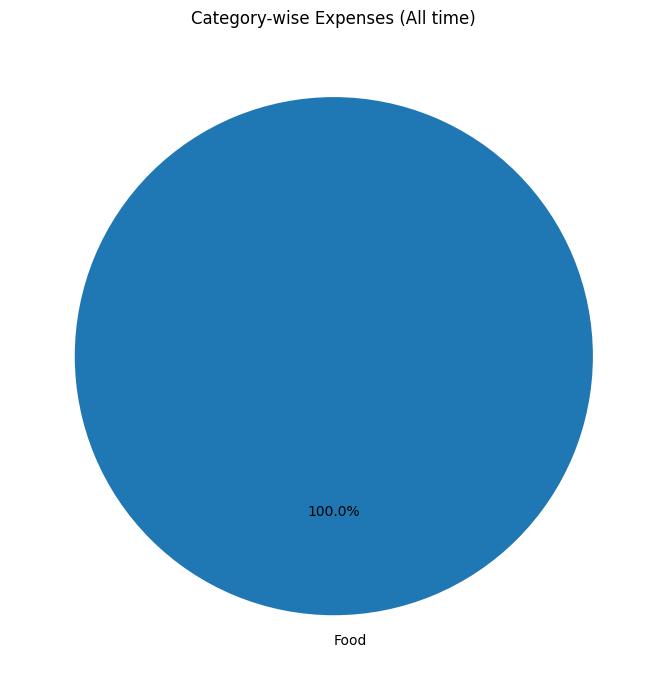

  ✓ Chart saved: charts/category_pie_all.png


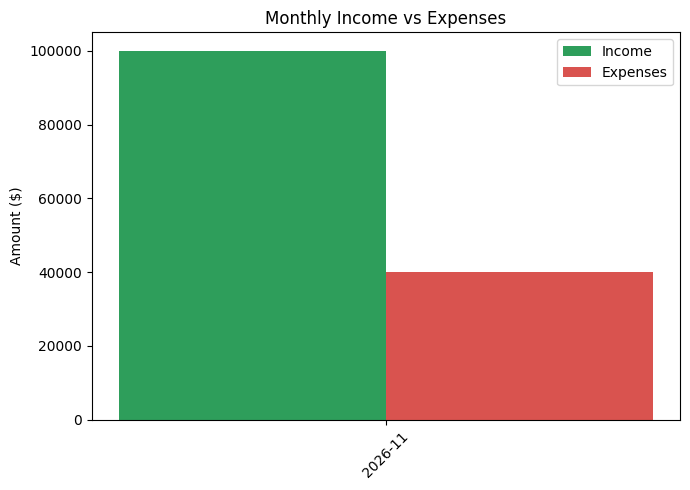

  ✓ Chart saved: charts/monthly_income_vs_expenses.png


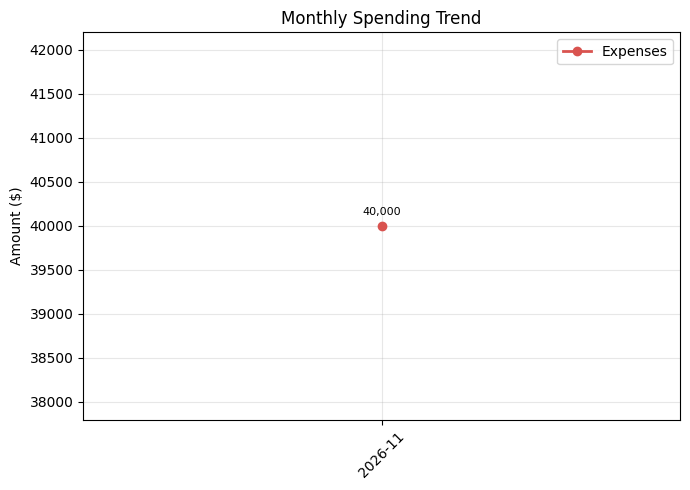

  ✓ Chart saved: charts/monthly_spending_trend.png

Press Enter to continue...

========== PERSONAL EXPENSE TRACKER ==========

 1. Add Income
 2. Add Expense
 3. View Transactions
 4. Search Transactions
 5. Set Monthly Budget
 6. Monthly Summary
 7. Monthly Spending Comparison
 8. Highest Expense Category
 9. Savings Calculator
10. View Charts
11. Export Reports
12. Exit

Enter your choice: 8

========== HIGHEST EXPENSE CATEGORY ==========
Month (YYYY-MM), 'all', or Enter = current month: all

  Category-wise spending (All time):
+----------+------------+--------+------------------------+
| Category |      Spent |  Share |                        |
+----------+------------+--------+------------------------+
| Food     | $40,000.00 | 100.0% | [████████████████████] |
+----------+------------+--------+------------------------+

  ★ Highest spending category: Food ($40,000.00)

Press Enter to continue...

========== PERSONAL EXPENSE TRACKER ==========

 1. Add Income
 2. Add Expense
 3. 

In [ ]:
main()